In [93]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [94]:
little_new = pd.read_csv("../EMG Recordings/little_finger 10mins.csv")
middle_new = pd.read_csv("../EMG Recordings/middle_finger_10mins.csv")
ring_new = pd.read_csv("../EMG Recordings/ring_finger_10mins.csv")
index_new = pd.read_csv("../EMG Recordings/index_finger_10mins.csv")
thumb_new = pd.read_csv("../EMG Recordings/thumb_finger_10mins.csv")

print("\nALL DATASETS LOADED")


ALL DATASETS LOADED


In [95]:
recordings = {
    "Little": little_new.head(60745),
    "Middle": middle_new.head(60745),
    "Ring": ring_new.head(60745),
    "Index": index_new.head(60745),
    "Thumb": thumb_new.head(60745)
}

In [96]:
for finger, data in recordings.items():
    print(f"{finger}: {data.shape}")
    assert len(data) == 60745, (
        f"{finger} has fewer than 60745 readings."
    )

Little: (60745, 3)
Middle: (60745, 3)
Ring: (60745, 3)
Index: (60745, 3)
Thumb: (60745, 3)


In [97]:
def create_batches(data, batch_size=10):
    signals = data[["emg1", "emg2"]].values
    batches = []

    for i in range(0, len(signals), batch_size):
        batch = signals[i:i + batch_size]
        if len(batch) == batch_size:
            batches.append(batch.flatten())
    return np.array(batches)

In [98]:
emg_features = []
finger_labels = []




for finger, data in recordings.items():

    batches = create_batches(data)

    for batch in batches:

        emg_features.append(batch)

        finger_labels.append(finger)


emg_features = np.array(emg_features)

finger_labels = np.array(finger_labels)


print("\nDataset Information")

print("Features:", emg_features.shape)

print("Labels:", finger_labels.shape)

print("\nClass distribution:")

print(pd.Series(finger_labels).value_counts())



Dataset Information
Features: (30370, 20)
Labels: (30370,)

Class distribution:
Little    6074
Middle    6074
Ring      6074
Index     6074
Thumb     6074
Name: count, dtype: int64


In [99]:
(
    train_features,
    test_features,
    train_labels,
    test_labels

) = train_test_split(

    emg_features,
    finger_labels,

    train_size=0.60,
    test_size=0.40,

    random_state=42,

    stratify=finger_labels
)


print("\nTraining samples:", len(train_features))

print("Testing samples:", len(test_features))



Training samples: 18222
Testing samples: 12148


In [100]:
scaler = StandardScaler()


train_features_scaled = scaler.fit_transform(
    train_features
)


test_features_scaled = scaler.transform(
    test_features
)


In [101]:
model = RandomForestClassifier(

    n_estimators=100,

    random_state=42
)



In [102]:

model.fit(
    train_features_scaled,
    train_labels
)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [103]:

predicted_fingers = model.predict(
    test_features_scaled
)


In [104]:
accuracy = accuracy_score(
    test_labels,
    predicted_fingers
)
print("RANDOM FOREST + SCALING")



print(f"Accuracy: {accuracy * 100:.2f}%")




RANDOM FOREST + SCALING
Accuracy: 65.32%


In [105]:

print("\nClassification Report:")


print(
    classification_report(
        test_labels,
        predicted_fingers,
        zero_division=0
    )
)



Classification Report:
              precision    recall  f1-score   support

       Index       0.57      0.58      0.57      2430
      Little       0.72      0.78      0.75      2429
      Middle       0.51      0.47      0.49      2430
        Ring       0.65      0.61      0.63      2430
       Thumb       0.80      0.83      0.81      2429

    accuracy                           0.65     12148
   macro avg       0.65      0.65      0.65     12148
weighted avg       0.65      0.65      0.65     12148



In [106]:
finger_names = [
    "Little",
    "Middle",
    "Ring",
    "Index",
    "Thumb"
]


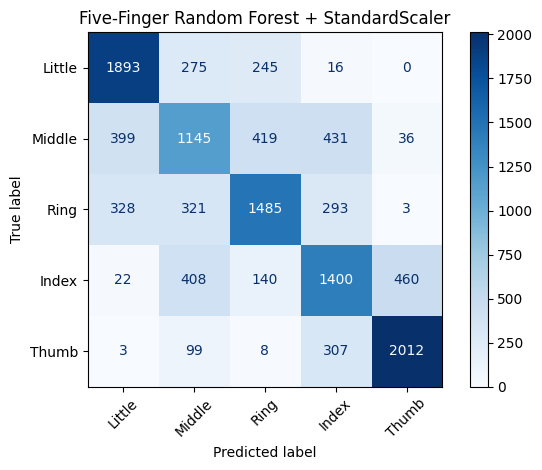

In [107]:
matrix = confusion_matrix(
    test_labels,
    predicted_fingers,
    labels=finger_names
)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=finger_names
)

display.plot(cmap="Blues")


plt.title("Five-Finger Random Forest + StandardScaler")


plt.xticks(rotation=45)


plt.tight_layout()


plt.show()






In [108]:

sample = test_features_scaled[0].reshape(1, -1)


prediction = model.predict(sample)


print("\nIndividual Batch Prediction")


print("Predicted:", prediction[0])


print("Actual:", test_labels[0])


Individual Batch Prediction
Predicted: Ring
Actual: Ring
